# HomeWork -4
## Objective
 In this homework, you will design a python class that encapsulates common univariate/bivariate analysis tasks. You will practice object oriented programing (OOP) while applying descriptive statistics and visualization to summarize your data and explore the relationship between two variables.

 - Use the example provided in the class activity and expand it. The initializer of the class should take data and print out its shape and column names.
 - Additionally, your class should include at least 5 methods (function) to do either univariate or bivariate analysis of your choice.
 - Provide markdowns or comments for each part of your code.  

  - Create an instance of your class using Penguin data and use it to analyze it.
  
  - For each analysis you perform, write 1-2 sentence before that function call that clearly state
    the question you are trying to answer with that analysis. For example: "In this analysis I want to see what is the average mass for each species."

  


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

penguins = sns.load_dataset('penguins')

In [ ]:
class DataAnalyzer:
    def __init__(self, df):
        #store data, print shapes, print column names
        self.df = df
        print('--- Dataset Loaded Successfully ---')
        print(f'Shape of Dataset (rows, columns): {self.df.shape}')
        print(f'Column Names: {list(self.df.columns)}\n')

    #method 1: missing values
    def check_miss_vals(self):
        #print total missing vals per column
        missing = self.df.isnull().sum()
        print('--- Number of Missing Values ---')
        print(missing[missing > 0])
        print('--------------------------------\n')

    #method 2: categorical vals
    def categorical(self, col_name):
        #show values for specific categorical variable
        print(f"--- Values for '{col_name}' ---")
        print(self.df[col_name].value_counts(dropna=False))
        print('------------------------------------\n')

    #method 3: numeric distribution plot
    def num_distr(self, col_name):
        #plots histogram for numeric var
        plt.figure(figsize=(7, 4))
        sns.histplot(data=self.df, x=col_name, kde=True, color='teal')
        plt.title(f"Distribution of {col_name.replace('_', ' ').title()}")
        plt.xlabel(col_name.replace('_', ' ').title())
        plt.ylabel('Frequency')
        plt.show()

    #method 4: grouped stats
    def compare_num_by_cat(self, num_col, cat_col):
        #calculate mean, median, and std fir numeric column grouped by a category
        stats = self.df.groupby(cat_col)[num_col].agg(['mean', 'median', 'std', 'count']).round(2)
        print(f'--- {num_col.replace('_', ' ').title()} Grouped by {cat_col.title()} ---')
        print(stats)
        print('-----------------------------------------------------------\n')

    #method 5: scatterplot w hue
    def both_var_rel(self, x_col, y_col, hue_col=None):
        #plot scatterplot b/w two numeric vars
        plt.figure(figsize=(8, 5))
        sns.scatterplot(data=self.df, x=x_col, y=y_col, hue=hue_col, palette='Set2', alpha=0.8)
        plt.title(f'{y_col.replace('_', ' ').title()} vs. {x_col.replace('_', " ").title()}')
        plt.xlabel(x_col.replace('_', " ").title())
        plt.ylabel(y_col.replace('_', " ").title())
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.show()

In [ ]:
analyzer = DataAnalyzer(penguins)

--- Dataset Loaded Successfully ---
Shape of Dataset (rows, columns): (344, 7)
Column Names: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']



For Analysis #1, I am trying to identify which columns in the dataset have missing values and the number of how many values are missing . This helps with deciding whether the data needs to be cleaned before performing any further analysis .

In [ ]:
#analysis 1
analyzer.check_miss_vals()

--- Number of Missing Values ---
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64
--------------------------------



For Analysis #2, I am trying to check and assess the overall sample distribution across different penguin species. This helps show whether the dataset is balanced or is focused/dominated by a specific species.

In [ ]:
#analysis 2
analyzer.categorical('species')

--- Values for 'species' ---
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64
------------------------------------



For Analysis #3, I am trying to inspect the overall distribution and shape of penguin flipper lengths. This helps show whether flipper lengths follow a standard distribution or show multiple peaks.

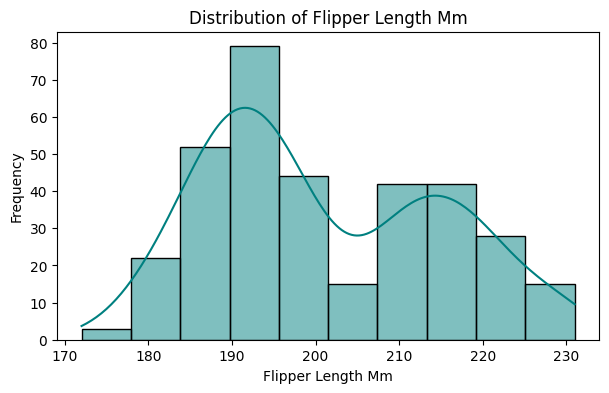

In [ ]:
# analysis 3
analyzer.num_distr('flipper_length_mm')

For Analysis #4, I am trying to calculate summary statistics for body mass categorized across each penguin species. This will show which species tends to be the heaviest on average.

In [ ]:
# analysis 4
analyzer.compare_num_by_cat(num_col='body_mass_g', cat_col='species')

--- Body Mass G Grouped by Species ---
              mean  median     std  count
species                                  
Adelie     3700.66  3700.0  458.57    151
Chinstrap  3733.09  3700.0  384.34     68
Gentoo     5076.02  5000.0  504.12    123
-----------------------------------------------------------



For Analysis #5, I am trying to look into the relationship between bill length and bill depth across different species. This helps with figuring out whether bill dimensions can clearly separate distinct species groups, or are more clustered together.

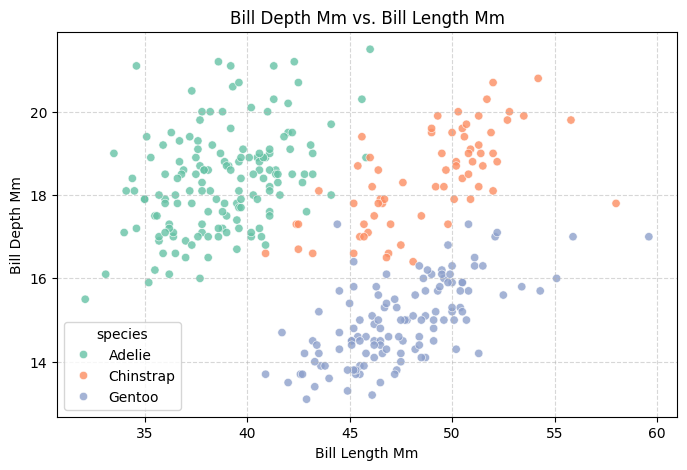

In [ ]:
analyzer.both_var_rel(x_col='bill_length_mm', y_col='bill_depth_mm', hue_col='species')